<a href="https://colab.research.google.com/github/Nitish-kumar19/Sales-Data-Cleaning/blob/main/SalesData.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df=pd.read_csv('sales_customer_orders_dirty.csv')
df

,Order_ID,Order_Date,Customer_Age,Gender,City,Product,Category,Quantity,Unit_Price,Payment_Method,Order_Status,Total_Amount
0,ORD001,2025-03-13,38.0,Other,Mumbai,Keyboard,Accessories,5,1086.04,Debit Card,Delivered,5430.20
1,ORD002,2025-06-01,20.0,Male,Chennai,Headphones,Accessories,5,1854.60,Credit Card,Pending,9273.00
2,ORD003,2025-01-21,50.0,Male,Pune,Mouse,Accessories,2,633.18,UPI,Delivered,1266.36
3,ORD004,2025-06-19,45.0,Other,Pune,Laptop,Electronics,3,56845.57,Credit Card,Pending,170536.71
4,ORD005,2025-03-05,NaN,Female,Kolkata,Headphones,Accessories,4,1807.69,Debit Card,Delivered,7230.76
...,...,...,...,...,...,...,...,...,...,...,...,...
115,ORD116,2025-03-15,50.0,Male,Pune,Phone,Electronics,2,24954.86,UPI,Delivered,49909.72
116,ORD117,2025-01-15,46.0,Female,Chennai,Keyboard,Accessories,5,1065.90,Debit Card,Delivered,5329.50
117,ORD118,2025-04-25,53.0,Male,Kolkata,Monitor,Electronics,2,10243.93,Debit Card,Delivered,20487.86
118,ORD119,2025-05-14,25.0,Other,Mumbai,Headphones,Accessories,2,1714.96,Credit Card,Delivered,3429.92


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 119 entries, 0 to 118
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        119 non-null    object 
 1   Order_Date      117 non-null    object 
 2   Customer_Age    119 non-null    float64
 3   Gender          119 non-null    object 
 4   City            119 non-null    object 
 5   Product         119 non-null    object 
 6   Category        119 non-null    object 
 7   Quantity        119 non-null    int64  
 8   Unit_Price      119 non-null    float64
 9   Payment_Method  117 non-null    object 
 10  Order_Status    119 non-null    object 
 11  Total_Amount    118 non-null    float64
dtypes: float64(3), int64(1), object(8)
memory usage: 12.1+ KB


In [9]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,2
Customer_Age,0
Gender,0
City,0
Product,0
Category,0
Quantity,0
Unit_Price,0
Payment_Method,2


In [5]:
df['Customer_Age'] = df['Customer_Age'].fillna(df['Customer_Age'].mean())


In [12]:
df['City'] = df['City'].fillna(df['City'].mode()[0]) # we use [0] because the data can have multiple modes this gives output in object with string values we just give the first value from that object

,City
0,Bengaluru


In [17]:
df.duplicated().sum()

np.int64(1)

In [19]:
df.drop_duplicates(inplace=True) # Remove the duplicate data

In [29]:
print(df['Gender'].unique())
print(df['City'].unique())
print(df['Order_Status'].unique())
print(df['Payment_Method'].unique())
print(df['Product'].unique())
print(df['Category'].unique())

['Other' 'Male' 'Female' 'female' 'MALE']
['Mumbai' 'Chennai' 'Pune' 'Kolkata' 'Delhi' 'Bengaluru' ' delhi '
 'MUMBAI']
['Delivered' 'Pending' 'Cancelled' 'deliverd' 'Returned']
['Debit Card' 'Credit Card' 'UPI' 'Cash' nan 'upi']
['Keyboard' 'Headphones' 'Mouse' 'Laptop' 'Phone' 'Monitor']
['Accessories' 'Electronics']


In [34]:
df['Gender'] = df['Gender'].str.strip().str.title() # this will remove extra space and make the first letter capital
df['City'] = df['City'].str.strip().str.title()
df['Order_Status'] = df['Order_Status'].str.strip().str.title()
df['Payment_Method'] = df['Payment_Method'].str.strip().str.title()
df['Product'] = df['Product'].str.strip().str.title()
df['Category'] = df['Category'].str.strip().str.title()


In [35]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 119 entries, 0 to 118
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        119 non-null    object 
 1   Order_Date      117 non-null    object 
 2   Customer_Age    119 non-null    float64
 3   Gender          119 non-null    object 
 4   City            119 non-null    object 
 5   Product         119 non-null    object 
 6   Category        119 non-null    object 
 7   Quantity        119 non-null    int64  
 8   Unit_Price      119 non-null    float64
 9   Payment_Method  117 non-null    object 
 10  Order_Status    119 non-null    object 
 11  Total_Amount    118 non-null    float64
dtypes: float64(3), int64(1), object(8)
memory usage: 12.1+ KB


In [43]:
df[df['Customer_Age']>100]
df[df['Quantity']<0]
df[df['Unit_Price']<0]

,Order_ID,Order_Date,Customer_Age,Gender,City,Product,Category,Quantity,Unit_Price,Payment_Method,Order_Status,Total_Amount
81,ORD082,2025-04-23,57.0,Male,Bengaluru,Headphones,Accessories,5,-500.0,Debit Card,Delivered,9286.65


In [45]:
df = df.drop(
    df[
    (df['Customer_Age']>100) |
    (df['Quantity']<0) |
    (df['Unit_Price']<0)
    ].index
)

In [47]:
df.info()
df

<class 'pandas.core.frame.DataFrame'>
Index: 116 entries, 0 to 118
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        116 non-null    object 
 1   Order_Date      114 non-null    object 
 2   Customer_Age    116 non-null    float64
 3   Gender          116 non-null    object 
 4   City            116 non-null    object 
 5   Product         116 non-null    object 
 6   Category        116 non-null    object 
 7   Quantity        116 non-null    int64  
 8   Unit_Price      116 non-null    float64
 9   Payment_Method  114 non-null    object 
 10  Order_Status    116 non-null    object 
 11  Total_Amount    115 non-null    float64
dtypes: float64(3), int64(1), object(8)
memory usage: 11.8+ KB


,Order_ID,Order_Date,Customer_Age,Gender,City,Product,Category,Quantity,Unit_Price,Payment_Method,Order_Status,Total_Amount
0,ORD001,2025-03-13,38.000000,Other,Mumbai,Keyboard,Accessories,5,1086.04,Debit Card,Delivered,5430.20
1,ORD002,2025-06-01,20.000000,Male,Chennai,Headphones,Accessories,5,1854.60,Credit Card,Pending,9273.00
2,ORD003,2025-01-21,50.000000,Male,Pune,Mouse,Accessories,2,633.18,Upi,Delivered,1266.36
3,ORD004,2025-06-19,45.000000,Other,Pune,Laptop,Electronics,3,56845.57,Credit Card,Pending,170536.71
4,ORD005,2025-03-05,43.008621,Female,Kolkata,Headphones,Accessories,4,1807.69,Debit Card,Delivered,7230.76
...,...,...,...,...,...,...,...,...,...,...,...,...
114,ORD115,2025-04-07,54.000000,Other,Delhi,Headphones,Accessories,4,2068.75,Credit Card,Delivered,8275.00
115,ORD116,2025-03-15,50.000000,Male,Pune,Phone,Electronics,2,24954.86,Upi,Delivered,49909.72
116,ORD117,2025-01-15,46.000000,Female,Chennai,Keyboard,Accessories,5,1065.90,Debit Card,Delivered,5329.50
117,ORD118,2025-04-25,53.000000,Male,Kolkata,Monitor,Electronics,2,10243.93,Debit Card,Delivered,20487.86


In [49]:
df['Total_Amount'] = (df['Quantity'] * df['Unit_Price'])

In [50]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 116 entries, 0 to 118
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        116 non-null    object 
 1   Order_Date      114 non-null    object 
 2   Customer_Age    116 non-null    float64
 3   Gender          116 non-null    object 
 4   City            116 non-null    object 
 5   Product         116 non-null    object 
 6   Category        116 non-null    object 
 7   Quantity        116 non-null    int64  
 8   Unit_Price      116 non-null    float64
 9   Payment_Method  114 non-null    object 
 10  Order_Status    116 non-null    object 
 11  Total_Amount    116 non-null    float64
dtypes: float64(3), int64(1), object(8)
memory usage: 15.9+ KB


In [52]:
df['Payment_Method'].isnull().sum()

np.int64(2)

In [53]:
df['Payment_Method'] = df['Payment_Method'].fillna('Unknown')

In [54]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 116 entries, 0 to 118
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order_ID        116 non-null    object 
 1   Order_Date      114 non-null    object 
 2   Customer_Age    116 non-null    float64
 3   Gender          116 non-null    object 
 4   City            116 non-null    object 
 5   Product         116 non-null    object 
 6   Category        116 non-null    object 
 7   Quantity        116 non-null    int64  
 8   Unit_Price      116 non-null    float64
 9   Payment_Method  116 non-null    object 
 10  Order_Status    116 non-null    object 
 11  Total_Amount    116 non-null    float64
dtypes: float64(3), int64(1), object(8)
memory usage: 15.9+ KB


In [55]:
df['Order_Date'].isnull().sum()

np.int64(2)

In [57]:
df['Order_Date'] = df['Order_Date'].fillna(
    df['Order_Date'].mode()[0]
    )

In [62]:
print(df['Order_Date'].dtype)

object


In [64]:
df['Order_Date'] = pd.to_datetime(
    df['Order_Date'],
    errors = 'coerce'
) # errors='coerce' this will convert the date in officical timestamp format (YYYY-MM-DD) and also if there is any non date data is there then this will gives null to them specially strings

1. Show the total sales ammount for each product.

2. Visualize the distribution of customer ages.

3. Compare the number of orders by order status.

4. Find potential outliers in Total_Amount

5. Analyze how total sales change over time.

6. Visualize correlations among numeric columns.

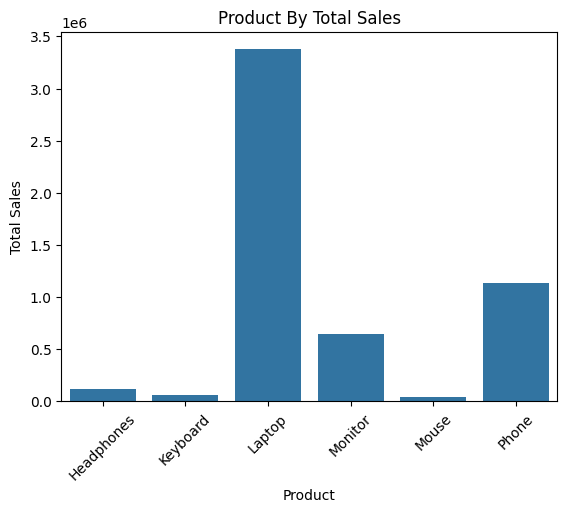

In [80]:
# 1. Show the total sales ammount for each product.
sales = df.groupby('Product')['Total_Amount'].sum().reset_index()
sns.barplot(x='Product', y='Total_Amount', data=sales)
plt.title("Product By Total Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

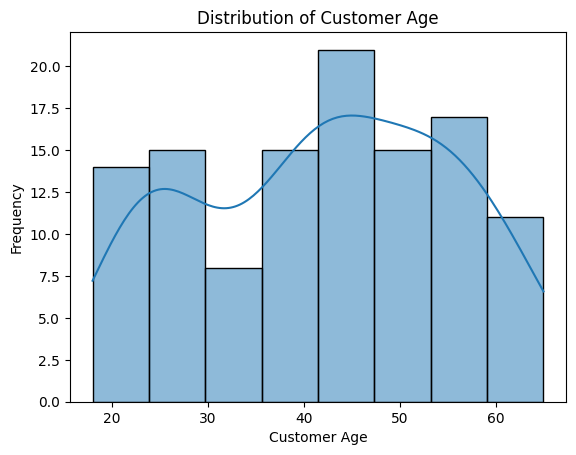

In [107]:
# 2. Visualize the distribution of customer ages.
sns.histplot(x ='Customer_Age',data = df,kde=True)
plt.title("Distribution of Customer Age")
plt.xlabel("Customer Age")
plt.ylabel("Frequency")
plt.show()

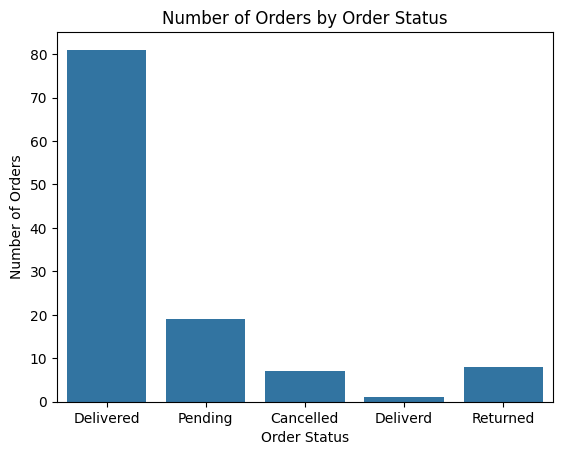

In [108]:
# 3. Compare the number of orders by order status.
sns.countplot(x='Order_Status',data=df)
plt.title("Number of Orders by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.show()

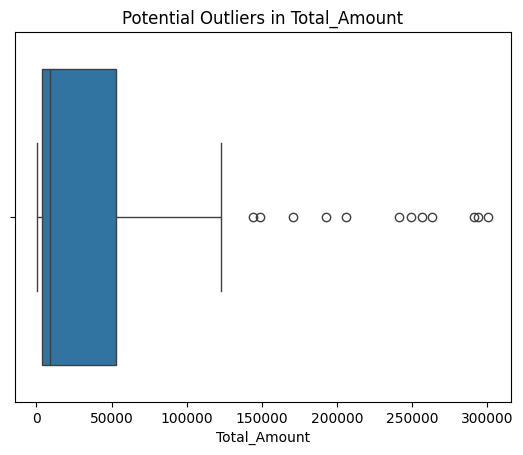

In [86]:
# 4. Find potential outliers in Total_Amount
sns.boxplot(x='Total_Amount',data=df)
plt.title("Potential Outliers in Total_Amount")
plt.xlabel("Total_Amount")
plt.show()


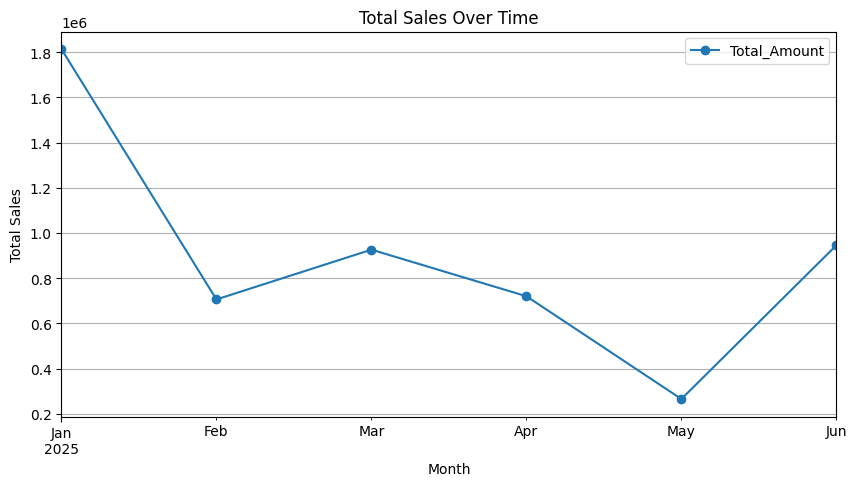

In [103]:
# 5. Analyze how total sales change over time.
df['Month'] = df['Order_Date'].dt.to_period('M')
monthly_sales = df.groupby('Month')['Total_Amount'].sum().reset_index()
monthly_sales.plot(x='Month', y='Total_Amount', kind='line', marker='o',figsize=(10,5))
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.title('Total Sales Over Time')
plt.grid()
plt.show()


<Figure size 1000x600 with 0 Axes>

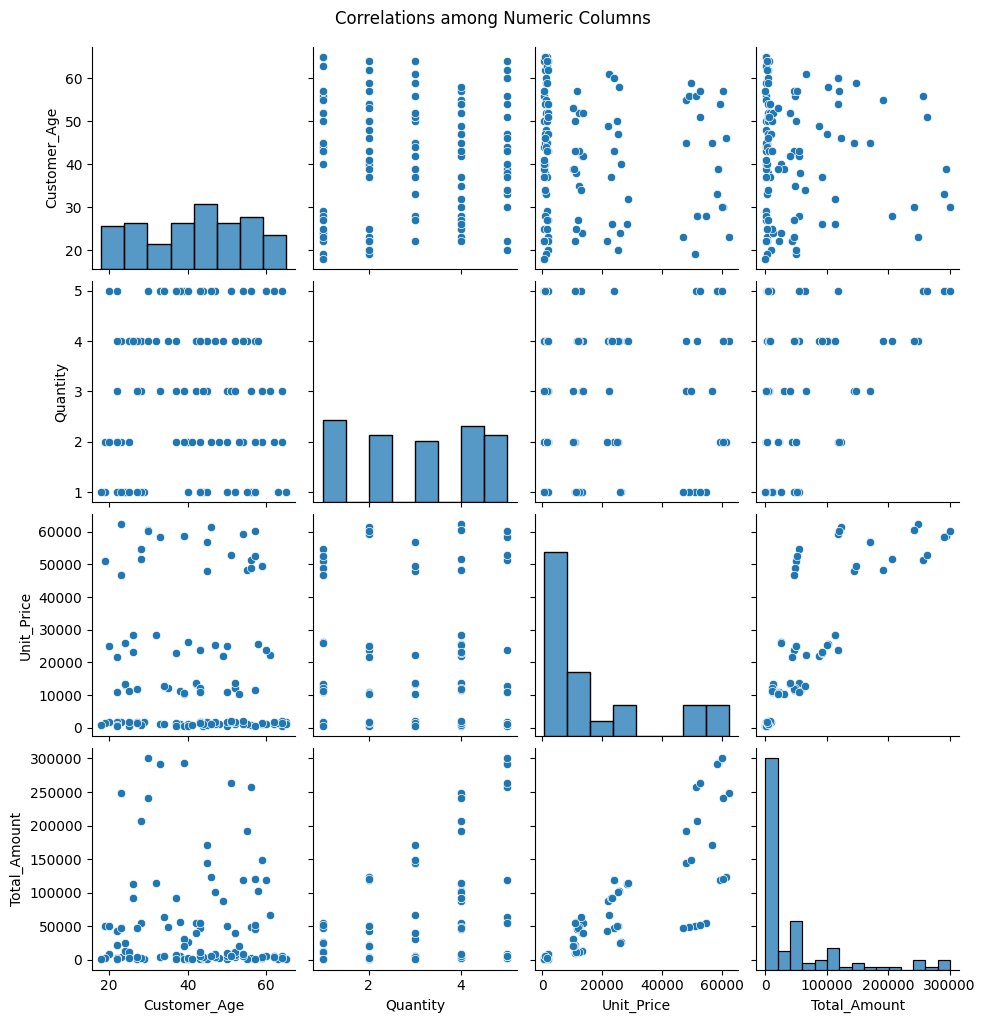

In [143]:
# 6. Visualize correlations among numeric columns.
plt.figure(figsize=(10,6))
sns.pairplot(df)
plt.suptitle("Correlations among Numeric Columns",y=1.02)
plt.show()

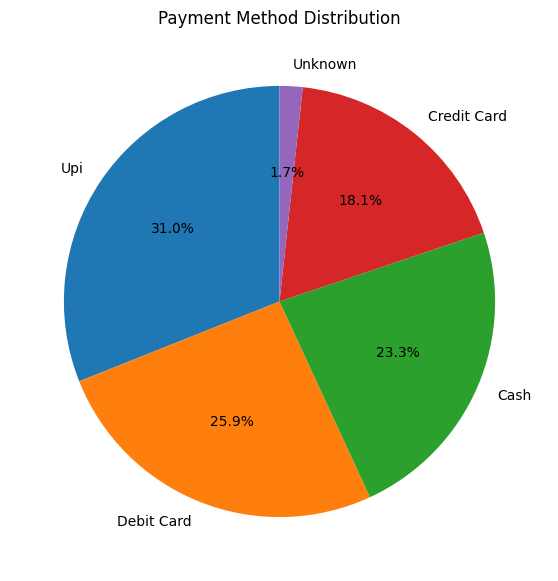

In [159]:
# Payment Methods distribution
payment = df['Payment_Method'].value_counts()
plt.figure(figsize=(7, 7))
plt.pie(payment,labels=payment.index,autopct='%1.01f%%',startangle=90)
plt.title("Payment Method Distribution")
plt.show()